In [27]:
import argparse
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as tck
import numpy as np

# plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.serif"] = ["Times New Roman"]

def load_curve(run_dir: Path, client: str, eval_name: str):
    """Load pre/post metrics for one run directory."""
    xs = []
    ys = []
    rounds = sorted(
        (run_dir / "eval_rounds").glob("round_*"),
        key=lambda p: int(p.name.split("_")[1]),
    )
    for rpath in rounds:
        rid = int(rpath.name.split("_")[1])
        if client == 'server_post_agg':
            fpath = rpath / f"{client}" / "TOFU_EVAL.json"
        else:
            fpath = rpath / f"{client}_{"post_train"}" / "TOFU_EVAL.json"
        if not fpath.exists():
            print(fpath)
            continue
        try:
            payload = json.loads(fpath.read_text())
        except json.JSONDecodeError:
            continue
        if eval_name not in payload:
            continue
        xs.append(rid)
        ys.append(payload[eval_name]["agg_value"])
    return xs, ys

In [34]:
plt.rcParams['text.usetex'] = True
size = (2.666666666666666666666666666666666666666666, 3)

method = "fedperm_only"
retain_split = "retain90"
fl_method = "FedAvg"
# fl_method = "FedProx"
# ul_method = "SimNPO"
ul_method = "GradAscent"
epoch = 1
ce0 = 1
alpha = 1
models = ["Llama-3.2-1B", "Qwen2.5-1.5B"]
# model = "Llama-3.2-1B"
me = 2

<>:17: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: "is not" with 'str' literal. Did you mean "!="?
<>:17: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: "is not" with 'str' literal. Did you mean "!="?
/tmp/ipykernel_3760/4186581010.py:17: SyntaxWarning: invalid escape sequence '\m'
  "$\mathcal{F}$+SOO": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_fliter",
/tmp/ipykernel_3760/4186581010.py:23: SyntaxWarning: invalid escape sequence '\m'
  "$\mathcal{F}$+SOO": "#1f77b4",
/tmp/ipykernel_3760/4186581010.py:2

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


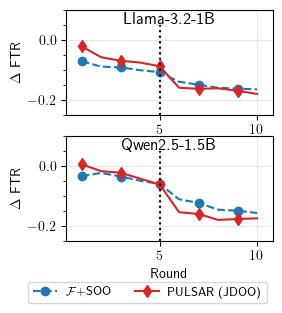

In [36]:
source_client = "client1"
# source_client = "server_post_agg"
# eval_name = "forget_Q_A_ROUGE"
# eval_name = "model_utility"
eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

fig, ax = plt.subplots(2, 1, figsize=size, sharex=False, sharey=True)

for i, model in enumerate(models):
    runs = {
        "Finetune": method_root / f"full_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "Retain": method_root / f"retain_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "$\mathcal{F}$+SOO": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_fliter",
        "Global": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_global",
        "PULSAR (JDOO)": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_filter1_CE1_Alpha1",
    }

    colors = {
        "$\mathcal{F}$+SOO": "#1f77b4",
        "Global": "#2ca02c",
        "PULSAR (JDOO)": "#d62728",
    }
    linestyles = {"$\mathcal{F}$+SOO": "--", "Global": "-.", "PULSAR (JDOO)": "-"}
    markers = {"$\mathcal{F}$+SOO": "o", "Global": "^", "PULSAR (JDOO)": "d"}

    for name, path in runs.items():
        if not path.exists():
            print(path)
            continue

        xs, ys = load_curve(path, client=source_client, eval_name=eval_name)
        if name == "Finetune":
            # xs = xs[:10]
            ys2 = np.array(ys[10:])
        elif name == "Retain":
            # xs = xs-10
            # xs = xs[:10]
            ys3 = np.array(ys[10:])
        elif name is not "Global":
            ax[i].plot(
                xs,
                ys-ys3,
                label=f"{name}",
                color=colors.get(name),
                linestyle=linestyles[name],
                marker=markers[name],
                markevery=me
            )

    # ax.vlines(11, 0, 0.22, colors="black", linestyles='dashed')
    # ax.vlines(15, 0, 0.22, colors="black", linestyles='dashed')
    ax[i].vlines(5, -0.25, 0.05, colors="black", linestyles=':')
    ax[i].set_xlim(xmin=0.2, xmax=10.8)
    ax[i].set_ylim(ymin=-0.25, ymax=0.1)
    ax[i].yaxis.set_minor_locator(tck.AutoMinorLocator())
    ax[i].grid(True, alpha=0.3)
    ax[i].set_ylabel("$\Delta$ FTR")
    ax[i].set_title(f"{model}", y=0.9, va="top")

ax[1].set_xlabel("Round")
handles, labels = ax[i].get_legend_handles_labels()
if labels:
    lgd = plt.legend(handles, labels, loc='lower right', bbox_to_anchor=(1,-0.65), ncol=2, fontsize=8.5)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.05)
out = f"ablation_{retain_split}_{fl_method}_{ul_method}_{eval_name}.eps"
plt.savefig(out, dpi=200, bbox_extra_artists=(lgd,), bbox_inches='tight')
# print(f"Saved plot to {out}")
plt.show()

<>:17: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: "is not" with 'str' literal. Did you mean "!="?
<>:17: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: "is not" with 'str' literal. Did you mean "!="?
/tmp/ipykernel_3760/3056938334.py:17: SyntaxWarning: invalid escape sequence '\m'
  "$\mathcal{F}$+SOO": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_fliter",
/tmp/ipykernel_3760/3056938334.py:23: SyntaxWarning: invalid escape sequence '\m'
  "$\mathcal{F}$+SOO": "#1f77b4",
/tmp/ipykernel_3760/3056938334.py:2

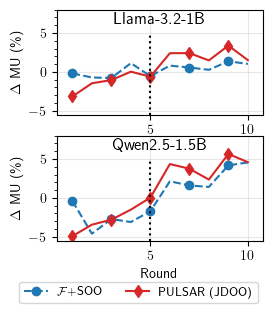

In [39]:
source_client = "client1"
# source_client = "server_post_agg"
# eval_name = "forget_Q_A_ROUGE"
eval_name = "model_utility"
# eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

fig, ax = plt.subplots(2, 1, figsize=size, sharex=False, sharey=True)

for i, model in enumerate(models):
    runs = {
        "Finetune": method_root / f"full_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "Retain": method_root / f"retain_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "$\mathcal{F}$+SOO": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_fliter",
        "Global": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_global",
        "PULSAR (JDOO)": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_filter1_CE1_Alpha1",
    }

    colors = {
        "$\mathcal{F}$+SOO": "#1f77b4",
        "Global": "#2ca02c",
        "PULSAR (JDOO)": "#d62728",
    }
    linestyles = {"$\mathcal{F}$+SOO": "--", "Global": "-.", "PULSAR (JDOO)": "-"}
    markers = {"$\mathcal{F}$+SOO": "o", "Global": "^", "PULSAR (JDOO)": "d"}

    for name, path in runs.items():
        if not path.exists():
            print(path)
            continue

        xs, ys = load_curve(path, client=source_client, eval_name=eval_name)
        if name == "Finetune":
            # xs = xs[:10]
            ys2 = np.array(ys[10:])
        elif name == "Retain":
            # xs = xs-10
            # xs = xs[:10]
            ys3 = np.array(ys[10:])
        elif name is not "Global":
            ax[i].plot(
                xs,
                100*(ys-ys2),
                label=f"{name}",
                color=colors.get(name),
                linestyle=linestyles[name],
                marker=markers[name],
                markevery=me
            )

    # ax.vlines(11, 0, 0.22, colors="black", linestyles='dashed')
    # ax.vlines(15, 0, 0.22, colors="black", linestyles='dashed')
    ax[i].vlines(5, -5.5, 5, colors="black", linestyles=':')
    ax[i].set_xlim(xmin=0.2, xmax=10.8)
    ax[i].set_ylim(ymin=-5.5, ymax=8)
    ax[i].yaxis.set_minor_locator(tck.AutoMinorLocator())
    ax[i].grid(True, alpha=0.3)
    ax[i].set_ylabel("$\Delta$ MU (\%)")
    ax[i].set_title(f"{model}", y=0.9, va="top")

ax[1].set_xlabel("Round")
handles, labels = ax[i].get_legend_handles_labels()
if labels:
    lgd = plt.legend(handles, labels, loc='lower right', bbox_to_anchor=(1,-0.65), ncol=2, fontsize=8.5)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.05)
out = f"ablation_{retain_split}_{fl_method}_{ul_method}_{eval_name}.eps"
plt.savefig(out, dpi=200, bbox_extra_artists=(lgd,), bbox_inches='tight')
# print(f"Saved plot to {out}")
plt.show()